### Imports

In [3]:
!which python
%pip install --upgrade pip
%pip install uproot
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install torch
%pip install scikit-learn
%pip install torchviz
!source /opt/homebrew/bin/thisroot.sh
!root --version

/Users/krishwu/.local/share/virtualenvs/WhitesonAIModelDistinguisher-zmfe64jY/bin/python
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
ROOT Version: 6.32.04
Built for macosxarm64 on Aug 14 2024, 03:00:41
From heads/master@tags/v6-32-04


In [4]:
import uproot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score, RocCurveDisplay, auc
from torchviz import make_dot

### Import Data

In [19]:
dataFile = open("data/v3/data.csv", "r", newline='')

data = np.genfromtxt(dataFile, delimiter=',')
dataLabels = data[:,2:]
data = data[:,0:2]

# data = StandardScaler().fit_transform(data)

pt = np.array([[item[0]] for item in data])
# dataLabels = np.array([item[0] for item in dataLabels])

data.shape
dataLabels.shape

(47440, 1)

In [20]:
# split data
X_train_numpy, X_test_numpy, y_train_numpy, y_test_numpy = train_test_split(data, dataLabels, test_size=0.25, random_state=123)
X_train = torch.tensor(X_train_numpy, dtype=torch.float32)
X_test = torch.tensor(X_test_numpy, dtype=torch.float32)
y_train = torch.tensor(y_train_numpy, dtype=torch.float32)
y_test = torch.tensor(y_test_numpy, dtype=torch.float32)

In [21]:
# pt_scaled = StandardScaler().fit_transform(pt)
X = torch.tensor(data, dtype=torch.float32)
XOnlyPt = torch.tensor(pt, dtype=torch.float32)
y = torch.tensor(dataLabels, dtype=torch.float32).reshape(-1, 1)

### Logistic Regression

In [69]:
clf = LogisticRegression(random_state=123)
clf.fit(X_train_numpy, y_train_numpy)

/Users/krishwu/.local/share/virtualenvs/WhitesonAIModelDistinguisher-zmfe64jY/lib/python3.12/site-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression(random_state=123)

In [70]:
y_pred = clf.predict(X_test_numpy)

acc = accuracy_score(y_test_numpy, y_pred)
print("Logistic Regression model accuracy (in %):", acc*100)

Logistic Regression model accuracy (in %): 76.56829679595279


In [71]:
confusion_matrix(y_test_numpy, y_pred)

array([[4909, 1023],
       [1756, 4172]])

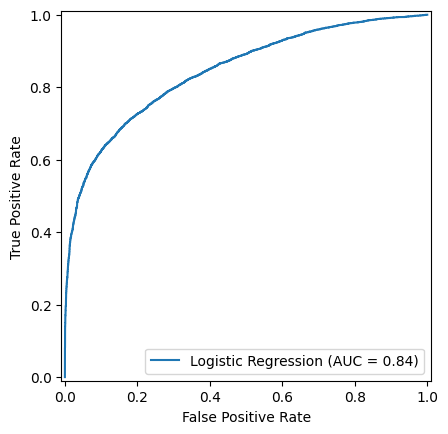

In [72]:
y_prob = clf.predict_proba(X_test_numpy)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test_numpy, y_prob)

roc_auc = auc(fpr, tpr)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Logistic Regression")
display.plot()

plt.show()

### Neural Network (from Website)

In [26]:
torch.manual_seed(123)

model = nn.Sequential(
    nn.Linear(2, 20),
    nn.ReLU(),
    nn.Linear(20, 20),
    nn.ReLU(),
    nn.Linear(20, 1),
    nn.Sigmoid()
)

model

Sequential(
  (0): Linear(in_features=2, out_features=20, bias=True)
  (1): ReLU()
  (2): Linear(in_features=20, out_features=20, bias=True)
  (3): ReLU()
  (4): Linear(in_features=20, out_features=1, bias=True)
  (5): Sigmoid()
)

In [27]:
loss_fn = nn.BCELoss() # binary cross entropy
# optimizer = optim.Adam(model.parameters(), lr=0.001)
optimizer = optim.Adam(model.parameters())
# optimizer = optim.SGD(model.parameters())

In [28]:
for i in range(10):
    print(X_train[i], y_train[i])

tensor([1.0175e+03, 6.1663e-01]) tensor([1.])
tensor([42.9031,  2.1819]) tensor([0.])
tensor([90.7821,  2.8813]) tensor([1.])
tensor([883.9923,   1.6540]) tensor([1.])
tensor([4.1643e+02, 2.8631e-01]) tensor([0.])
tensor([664.4886,   3.0245]) tensor([1.])
tensor([1025.0676,    3.3837]) tensor([1.])
tensor([714.7155,   0.9834]) tensor([0.])
tensor([431.6087,   0.7892]) tensor([0.])
tensor([111.0113,   1.3991]) tensor([0.])


In [29]:
n_epochs = 100
batch_size = 10

for epoch in range(n_epochs):
    for i in range(0, len(X), batch_size):
        Xbatch = X_train[i:i+batch_size]
        # Xbatch = X
        y_prediction = model(Xbatch)
        ybatch = y_train[i:i+batch_size]
        # ybatch = y
        loss = loss_fn(y_prediction, ybatch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f"Finished epoch {epoch}, latest loss {loss}")

Finished epoch 0, latest loss nan
Finished epoch 1, latest loss nan
Finished epoch 2, latest loss nan
Finished epoch 3, latest loss nan
Finished epoch 4, latest loss nan
Finished epoch 5, latest loss nan
Finished epoch 6, latest loss nan
Finished epoch 7, latest loss nan
Finished epoch 8, latest loss nan
Finished epoch 9, latest loss nan
Finished epoch 10, latest loss nan
Finished epoch 11, latest loss nan
Finished epoch 12, latest loss nan
Finished epoch 13, latest loss nan
Finished epoch 14, latest loss nan
Finished epoch 15, latest loss nan
Finished epoch 16, latest loss nan
Finished epoch 17, latest loss nan
Finished epoch 18, latest loss nan
Finished epoch 19, latest loss nan
Finished epoch 20, latest loss nan
Finished epoch 21, latest loss nan
Finished epoch 22, latest loss nan
Finished epoch 23, latest loss nan
Finished epoch 24, latest loss nan
Finished epoch 25, latest loss nan
Finished epoch 26, latest loss nan
Finished epoch 27, latest loss nan
Finished epoch 28, latest loss

In [30]:
# compute accuracy (no_grad is optional)
with torch.no_grad():
    y_prediction = model(X_train)

accuracy = (y_prediction.round() == y_train).float().mean()
print(f"Accuracy (train) {accuracy}")

Accuracy (train) 0.7625351548194885


In [31]:
# compute accuracy (no_grad is optional)
with torch.no_grad():
    y_prediction = model(X_test)

accuracy = (y_prediction.round() == y_test).float().mean()
print(f"Accuracy (test) {accuracy}")

Accuracy (test) 0.764839768409729


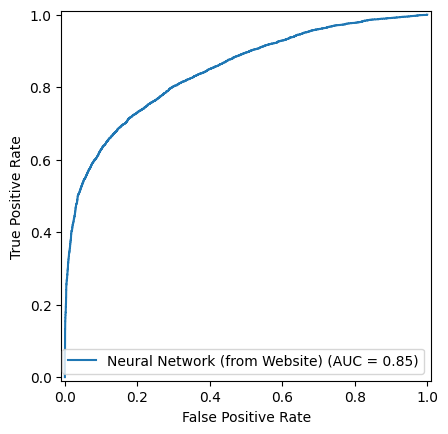

In [32]:
y_prob = model(X_test)

fpr, tpr, thresholds = roc_curve(y_test.numpy(), y_prob.detach().numpy())

roc_auc = auc(fpr, tpr)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Neural Network (from Website)")
display.plot()

plt.show()

### Neural Network (from Jupyter Notebook)

In [162]:
torch.manual_seed(123)
net = torch.nn.Sequential(
    torch.nn.Linear(2, 20),
    torch.nn.ReLU(),
    torch.nn.Linear(20, 25),
    torch.nn.ReLU(),
    torch.nn.Linear(25, 1),
)

torch.save(net.state_dict(), 'net.pth')

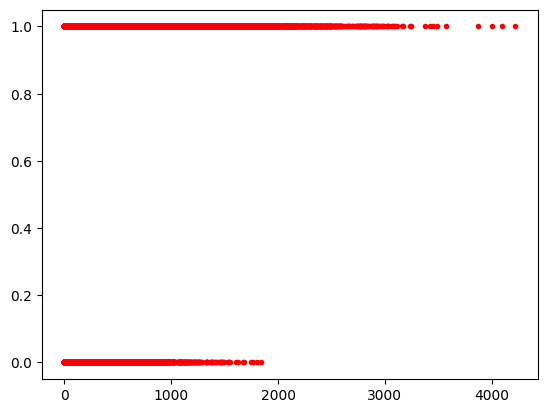

In [163]:
# y_pred = net(X_test_tensor).detach()
# plt.plot(X_test_tensor.numpy(), y_pred.numpy(), 'k.')
plt.plot(X_test.numpy(), y_test.numpy(), 'r.')

In [164]:
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.SGD(net.parameters(), lr=0.1, momentum=0.9)

/var/folders/4h/btz0vs815bgflhf3shpm_mwr0000gn/T/ipykernel_91139/3779730708.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load('net.pth'))


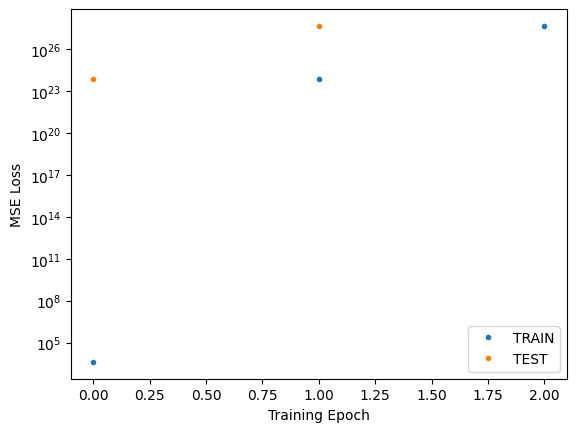

In [165]:
torch.manual_seed(123)
net.load_state_dict(torch.load('net.pth'))
losses_train, losses_test = [], []
for epoch in range(200):
    # Calculate the loss on the training sample.
    net.train() # configure the model for training
    y_pred = net(X_train)
    loss = loss_fn(y_pred, y_train)
    # Update the parameters.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # Save the training loss after each epoch.
    losses_train.append(loss.data)
    # Calculate and save the test loss after each epoch.
    net.eval() # configure the model for evaluation (testing)
    y_pred = net(X_test)
    losses_test.append(loss_fn(y_pred, y_test).data)
plt.plot(losses_train, '.', label='TRAIN')
plt.plot(losses_test, '.', label='TEST')
plt.legend()
plt.xlabel('Training Epoch')
plt.ylabel('MSE Loss')
plt.yscale('log')

In [171]:
y_prob = net(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_prob.detach().numpy())

roc_auc = auc(fpr, tpr)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Logistic Regression")
display.plot()

plt.show()

ValueError: Input contains NaN.

In [167]:
xy_train = torch.utils.data.TensorDataset(X_train, y_train)
loader = torch.utils.data.DataLoader(xy_train, batch_size=5, shuffle=True)

In [168]:
for batch_num, (x_batch, y_batch) in enumerate(loader):
    if batch_num < 2 or batch_num >= len(loader) - 2:
        print(f'BATCH {batch_num}:\n  x_batch[:,0] = {x_batch[:,0]}\n  y_batch[:,0] = {y_batch[:,0]}.')
    elif batch_num == 2:
        print('\n...\n')

BATCH 0:
  x_batch[:,0] = tensor([114.1813, 267.2749, 486.9599, 614.6402, 438.9518])
  y_batch[:,0] = tensor([0., 0., 0., 1., 1.]).
BATCH 1:
  x_batch[:,0] = tensor([692.1775, 519.2643, 137.5190, 451.1913, 157.5524])
  y_batch[:,0] = tensor([1., 1., 0., 0., 0.]).

...

BATCH 7114:
  x_batch[:,0] = tensor([1146.6049, 1230.3126,  407.2198,   93.5381,  210.0697])
  y_batch[:,0] = tensor([0., 1., 1., 1., 0.]).
BATCH 7115:
  x_batch[:,0] = tensor([ 212.0699,  412.7570, 1425.8595, 2055.8821,   50.3666])
  y_batch[:,0] = tensor([0., 1., 1., 1., 0.]).


/var/folders/4h/btz0vs815bgflhf3shpm_mwr0000gn/T/ipykernel_91139/1924087504.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load('net.pth'))


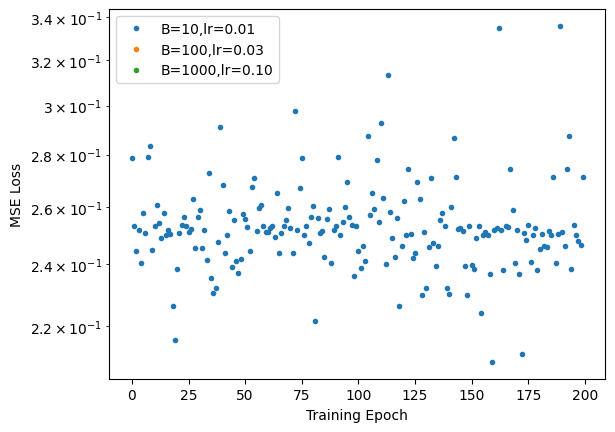

In [169]:
torch.manual_seed(123)
net.train()
for batch_size, learning_rate in zip((10, 100, 1000), (0.01, 0.03, 0.1)):
    optimizer = torch.optim.SGD(net.parameters(), lr=learning_rate, momentum=0.9)
    net.load_state_dict(torch.load('net.pth'))
    loader = torch.utils.data.DataLoader(xy_train, batch_size=batch_size, shuffle=True)
    losses = []
    for epoch in range(200):
        for x_batch, y_batch in loader:
            y_pred = net(x_batch)
            optimizer.zero_grad()
            loss = loss_fn(y_pred, y_batch)
            loss.backward()
            optimizer.step()
        losses.append(loss.data)
    plt.plot(losses, '.', label=f'B={batch_size},lr={learning_rate:.2f}')
plt.legend()
plt.xlabel('Training Epoch')
plt.ylabel('MSE Loss')
plt.yscale('log')